# Experiment 3: does the old Ballon d'Or format affect prediction quality?

Builds on v2 and v2.1. From 2022 the award moved from a calendar-year window with about 175 juror nations (2016-2021) to an August-July season window with the FIFA top 100. Does training on the 2016-2021 editions help or hurt predictions of 2022-2025?

**Design.** Score the four season editions under three training sets, everything else (v2.1 features F1-F12, folds, lambda grid, seeds) held fixed:

| Run | Trains on | Role |
|---|---|---|
| E3-S | the other 3 season editions | season only |
| E3-A | the other 8 editions | all formats (v2.1, reproduced to 4e-16) |
| E3-C | the 5 calendar editions | pure transfer |

Mirror check on 2016-2021: E3-Cself (other 4 calendar), E3-A, E3-Scal (4 season editions).

**Reading rules (pre-registered).** Four held-out editions only: differences in mean log-likelihood under about 0.03 per voted player are within noise. Claim an effect only if the paired 90% interval excludes 0. Winner rank and top-1 rest on four winners. The jury, window and ballot changes all coincide with the format change, so nothing here attributes a difference to the format itself.

Everything below reads CSVs from `results/v3/`, which `src/model/run_v3.py` and `run_v3_format.py` write. No 2026 outcome is used in sections 1-3.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
R = Path('results/v3')
by_fold = pd.read_csv(R/'metrics_by_fold_v3.csv')
summary = pd.read_csv(R/'metrics_summary_v3.csv')
paired = pd.read_csv(R/'paired_runs_v3.csv')
tuning = pd.read_csv(R/'tuning_by_fold_v3.csv')
coefs = pd.read_csv(R/'coefficients_by_format.csv')
inter = pd.read_csv(R/'format_interactions.csv')
grid = pd.read_csv(R/'feature_vs_data_grid.csv')
SEASON_RUNS = ['E3-S','E3-A','E3-C']; MIRROR_RUNS = ['E3-Cself','E3-A','E3-Scal']

## 1. Back-test on the season editions (2022-2025)

Held-out Plackett-Luce log-likelihood per voted player (higher is better). 2022-2023 are 5-pick ballots and 2024-2025 are 10-pick (descriptive split).

In [2]:
s = summary[(summary.subset=='season4') & (summary.metric=='heldout_ll')]
s.set_index(['model','run'])[['mean','mean_5pick_2022_23','mean_10pick_2024_25','fold_2022','fold_2023','fold_2024','fold_2025']].round(4).sort_index()

mean  mean_5pick_2022_23  mean_10pick_2024_25  fold_2022  fold_2023  fold_2024  fold_2025
model run                                                                                              
B1    E3-A -2.4233             -2.6353              -2.2113    -2.8087    -2.4619    -2.2114    -2.2112
      E3-C -2.4794             -2.6698              -2.2890    -2.8749    -2.4647    -2.2581    -2.3199
      E3-S -2.4634             -2.6737              -2.2531    -2.8600    -2.4874    -2.3214    -2.1849
M1    E3-A -2.2441             -2.3916              -2.0966    -2.4470    -2.3362    -2.0584    -2.1349
      E3-C -2.3329             -2.4885              -2.1774    -2.5894    -2.3875    -2.1252    -2.2296
      E3-S -2.2512             -2.3845              -2.1178    -2.3809    -2.3881    -2.0178    -2.2178
X1    E3-A -2.2638             -2.3768              -2.1508    -2.4136    -2.3400    -2.1284    -2.1732
      E3-C -2.3044             -2.3867              -2.2222    -2.3722    -2.4012    -2.1920    -2.2524
      E3-S -2.3281             -2.4165              -2.2398    -2.5350    -2.2979    -2.1976    -2.2819

In [3]:
other = ['winner_rank','top3_overlap','top10_acc','ndcg10','spearman']
t = summary[(summary.subset=='season4') & summary.metric.isin(other)].pivot_table(index=['model','run'], columns='metric', values='mean')
t[other].round(3)

metric      winner_rank  top3_overlap  top10_acc  ndcg10  spearman
model run                                                         
B1    E3-A         2.25          1.75      0.725   0.891     0.768
      E3-C         2.50          1.50      0.750   0.873     0.738
      E3-S         2.75          1.75      0.775   0.874     0.769
M1    E3-A         2.50          2.00      0.750   0.902     0.776
      E3-C         2.50          1.75      0.675   0.873     0.749
      E3-S         2.25          2.00      0.750   0.887     0.756
X1    E3-A         3.00          2.00      0.800   0.919     0.770
      E3-C         3.00          1.75      0.775   0.878     0.728
      E3-S         3.25          1.75      0.725   0.837     0.717

## 2. Paired differences (within-edition bootstrap, 1,000 draws, same draws across runs)

`first - second`, 90% interval, and the number of folds where each is better. A positive difference favours the first run.

In [4]:
p = paired[(paired.subset=='season4') & (paired.metric=='heldout_ll')]
p[['model','contrast','mean_diff','lo90','hi90','excludes_zero','folds_first_better','folds_second_better']].round(4).reset_index(drop=True)

,model,contrast,mean_diff,lo90,hi90,excludes_zero,folds_first_better,folds_second_better
0,M1,E3-S - E3-A,-0.0033,-0.0511,0.0453,False,2,2
1,M1,E3-C - E3-S,-0.0789,-0.1496,-0.0037,True,1,3
2,M1,E3-C - E3-A,-0.0822,-0.1211,-0.0393,True,0,4
3,X1,E3-S - E3-A,-0.0593,-0.1208,0.0062,False,1,3
4,X1,E3-C - E3-S,0.0175,-0.0728,0.1025,False,3,1
5,X1,E3-C - E3-A,-0.0418,-0.0973,0.0172,False,1,3
6,B1,E3-S - E3-A,-0.0314,-0.0961,0.0280,False,1,3
7,B1,E3-C - E3-S,-0.0208,-0.0985,0.0612,False,2,2
8,B1,E3-C - E3-A,-0.0523,-0.0898,-0.0140,True,0,4


In [5]:
p2 = paired[(paired.subset=='season4') & (paired.model=='M1')]
p2.pivot_table(index='metric', columns='contrast', values='mean_diff').round(4)

contrast,E3-C - E3-A,E3-C - E3-S,E3-S - E3-A
metric,,,
heldout_ll,-0.0822,-0.0789,-0.0033
ndcg10,-0.0309,-0.0205,-0.0105
pairwise_acc,-0.0199,-0.0133,-0.0066
spearman,-0.0291,-0.0091,-0.0200
top10_acc,-0.0427,-0.0382,-0.0044
top3_overlap,-0.1732,-0.1508,-0.0225


## 3. Features versus data (M1, 2022-2025 folds)

The row difference (v1 to v2.1 features, season editions only) is the effect of the features. The column difference (season only to all editions) is the effect of adding the old format.

In [6]:
grid.round(4)

,features,training_data,heldout_ll_2022_25,source
0,v1 features,season editions only,-2.3348,results/metrics_summary.csv (v1 M1)
1,v1 features,all editions,NaN,not possible: no xG before 2021
2,v2.1 features,season editions only,-2.2512,E3-S
3,v2.1 features,all editions,-2.2441,"E3-A (v2.1, reproduced)"
4,v2.1 features,calendar editions only,-2.3329,E3-C
5,v2 features,season editions only,-2.2773,results/v2 M1-season4
6,v2 features,all editions,-2.2753,"results/v2 M1, 2022-2025 folds"


## 4. Mirror check: scoring the calendar editions (2016-2021)

In [7]:
m = summary[(summary.subset=='calendar5') & (summary.metric=='heldout_ll')]
m.set_index(['model','run'])[['mean','fold_2016','fold_2017','fold_2018','fold_2019','fold_2021']].round(4).sort_index()

mean  fold_2016  fold_2017  fold_2018  fold_2019  fold_2021
model run                                                                    
B1    E3-A     -2.6173    -2.9944    -2.4289    -2.6188    -2.4073    -2.6371
      E3-Cself -2.6469    -3.0084    -2.5125    -2.5609    -2.5020    -2.6508
      E3-Scal  -2.6085    -3.0284    -2.3904    -2.6569    -2.3033    -2.6637
M1    E3-A     -2.4193    -2.6611    -2.2503    -2.4934    -2.1829    -2.5086
      E3-Cself -2.4325    -2.7302    -2.2557    -2.4596    -2.2525    -2.4647
      E3-Scal  -2.4325    -2.7254    -2.2596    -2.5459    -2.1776    -2.4541
X1    E3-A     -2.3874    -2.7791    -2.1797    -2.3520    -2.2459    -2.3804
      E3-Cself -2.4346    -2.7329    -2.2206    -2.3886    -2.3597    -2.4714
      E3-Scal  -2.4820    -3.0684    -2.3077    -2.4871    -2.1649    -2.3818

In [8]:
q = paired[(paired.subset=='calendar5') & (paired.metric=='heldout_ll')]
q[['model','contrast','mean_diff','lo90','hi90','excludes_zero','folds_first_better','folds_second_better']].round(4).reset_index(drop=True)

,model,contrast,mean_diff,lo90,hi90,excludes_zero,folds_first_better,folds_second_better
0,M1,E3-Cself - E3-A,-0.0151,-0.0628,0.0289,False,2,3
1,M1,E3-Scal - E3-Cself,0.0046,-0.0616,0.0742,False,3,2
2,M1,E3-Scal - E3-A,-0.0104,-0.0431,0.0218,False,2,3
3,X1,E3-Cself - E3-A,-0.0463,-0.0986,0.0035,False,1,4
4,X1,E3-Scal - E3-Cself,-0.0306,-0.1102,0.0559,False,2,3
5,X1,E3-Scal - E3-A,-0.0769,-0.1288,-0.0266,True,1,4
6,B1,E3-Cself - E3-A,-0.0317,-0.0730,0.0077,False,1,4
7,B1,E3-Scal - E3-Cself,0.0400,-0.0165,0.0974,False,2,3
8,B1,E3-Scal - E3-A,0.0083,-0.0302,0.0484,False,2,3


Selected ridge penalty per fold (M1). E3-S tunes on 3 inner folds of 2 editions; E3-C on 5 calendar editions.

In [9]:
tuning[tuning.model=='M1'].pivot_table(index='fold', columns='run', values='lambda_or_alpha').round(2)

run,E3-A,E3-C,E3-Cself,E3-S,E3-Scal
fold,,,,,
2016,10.00,NaN,10.0,NaN,4.64
2017,4.64,NaN,10.0,NaN,4.64
2018,10.00,NaN,10.0,NaN,4.64
2019,10.00,NaN,10.0,NaN,4.64
2021,4.64,NaN,10.0,NaN,4.64
2022,4.64,10.0,NaN,10.00,NaN
2023,4.64,10.0,NaN,4.64,NaN
2024,10.00,10.0,NaN,4.64,NaN
2025,10.00,10.0,NaN,4.64,NaN


## 5. Did the drivers change with the format?

### 5.1 Coefficients by format

M1 fitted at one fixed penalty (the median lambda across the nine E3-A folds, 10.0) on the 4 season editions and on the 5 calendar editions. Intervals are 90% within-edition bootstrap (500 draws). The difference is season minus calendar, on independent bootstrap draws (the two sets of editions are disjoint). The F10 residualiser is fitted separately on each set, so F10 is not strictly like for like.

In [10]:
cols = ['feature','beta_season','boot_lo90_season','boot_hi90_season','beta_calendar','boot_lo90_calendar','boot_hi90_calendar','diff_season_minus_calendar','diff_lo90','diff_hi90','diff_excludes_zero']
coefs[cols].round(3)

,feature,beta_season,boot_lo90_season,boot_hi90_season,beta_calendar,boot_lo90_calendar,boot_hi90_calendar,diff_season_minus_calendar,diff_lo90,diff_hi90,diff_excludes_zero
0,F1_attack,0.113,-0.026,0.322,0.085,-0.061,0.277,0.028,-0.198,0.272,False
1,F2_form_rating,0.085,-0.078,0.239,0.154,-0.004,0.303,-0.069,-0.269,0.159,False
2,F3_big_stage,0.306,0.155,0.479,0.101,-0.066,0.247,0.205,-0.005,0.440,False
3,F4_major_titles,0.400,0.248,0.513,0.268,0.128,0.434,0.132,-0.115,0.302,False
4,F5_other_honors,0.208,0.104,0.357,0.071,-0.048,0.231,0.136,-0.060,0.326,False
5,F6_team_strength,0.328,0.189,0.483,0.102,-0.054,0.245,0.226,0.029,0.459,True
6,F7_prior_standing,0.137,-0.004,0.312,0.112,-0.011,0.271,0.025,-0.163,0.240,False
7,F8_defending_winner,-0.163,-0.243,0.000,0.098,0.026,0.130,-0.260,-0.326,-0.046,True
8,F9_fame,0.390,0.229,0.565,0.486,0.336,0.641,-0.096,-0.334,0.143,False
9,F10_season_attention,0.178,0.003,0.305,-0.031,-0.171,0.141,0.209,-0.042,0.405,False


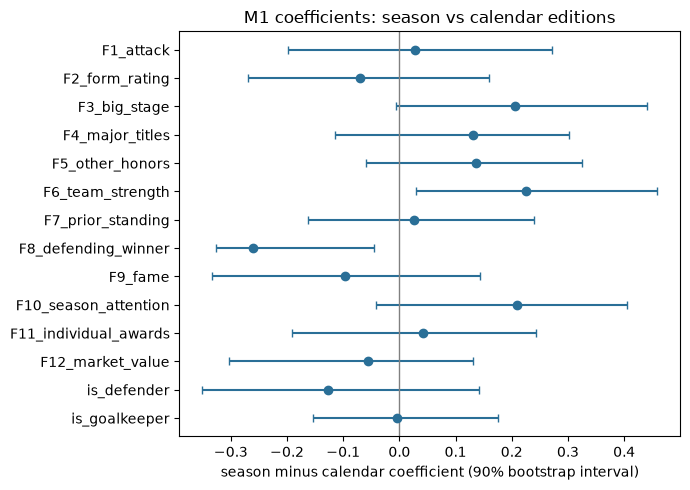

In [11]:
fig, ax = plt.subplots(figsize=(7, 5))
y = np.arange(len(coefs))[::-1]
ax.errorbar(coefs.diff_season_minus_calendar, y, xerr=[coefs.diff_season_minus_calendar-coefs.diff_lo90, coefs.diff_hi90-coefs.diff_season_minus_calendar], fmt='o', color='#2a6f97', capsize=3)
ax.axvline(0, color='grey', lw=1); ax.set_yticks(y); ax.set_yticklabels(coefs.feature)
ax.set_xlabel('season minus calendar coefficient (90% bootstrap interval)'); ax.set_title('M1 coefficients: season vs calendar editions')
plt.tight_layout(); plt.show()

Two of fourteen differences exclude zero at 90% (F6 team strength, F8 defending winner). With fourteen intervals, about one is expected to exclude zero by chance, so these are weak evidence. F8 rests on very few defending-winner rows per format.

### 5.2 Pooled format-interaction test

M1 fitted on all nine editions with `feature x is_season` added, one block at a time. A positive interaction means the feature counts more in the season format. Interaction coefficients are penalised at the tuned lambda, so they are shrunk. The held-out change is leave-one-edition-out on 2022-2025 against the base M1 (E3-A), with a paired 90% interval.

In [12]:
inter[['block','feature','beta','bootstrap_lo90','bootstrap_hi90','laplace_lo90','laplace_hi90','excludes_zero','lambda']].round(3)

,block,feature,beta,bootstrap_lo90,bootstrap_hi90,laplace_lo90,laplace_hi90,excludes_zero,lambda
0,F9-F10 fame and attention,F9_fame_x_season,0.025,-0.115,0.267,-0.192,0.242,False,10.0
1,F9-F10 fame and attention,F10_season_attention_x_season,0.182,0.001,0.332,-0.030,0.394,True,10.0
2,F11 awards,F11_individual_awards_x_season,0.104,-0.058,0.280,-0.120,0.328,False,10.0
3,F4 major titles,F4_major_titles_x_season,0.264,0.085,0.435,0.060,0.468,True,10.0
4,F1 attack,F1_attack_x_season,-0.029,-0.192,0.151,-0.244,0.186,False,10.0


In [13]:
inter.drop_duplicates('block')[['block','delta_heldout_ll_2022_25','delta_lo90','delta_hi90','folds_better','delta_by_fold']].round(4).reset_index(drop=True)

,block,delta_heldout_ll_2022_25,delta_lo90,delta_hi90,folds_better,delta_by_fold
0,F9-F10 fame and attention,0.0035,-0.0258,0.0351,3,2022:-0.0321 2023:+0.0261 2024:+0.0104 2025:+0...
1,F11 awards,-0.0007,-0.0153,0.0166,3,2022:+0.0050 2023:-0.0163 2024:+0.0034 2025:+0...
2,F4 major titles,0.0197,-0.0111,0.0425,4,2022:+0.0326 2023:+0.0088 2024:+0.0247 2025:+0...
3,F1 attack,-0.0044,-0.0164,0.0099,1,2022:-0.0018 2023:-0.0140 2024:+0.0001 2025:-0...


### 5.3 Confounds (stated, not separated)

The format change coincides with: the jury change (about 175 nations to the FIFA top 100); the window change (calendar year to August-July, with T2 available from 2022); and, within the season era, the ballot change (5 picks in 2022-2023, 10 from 2024). This experiment measures the combined effect of moving from the 2016-2021 setting to the 2022-2025 setting and cannot attribute it to any one of them. The 5-pick versus 10-pick split above is descriptive only.

## 6. 2026 (EXPLORATORY, post-hoc)

The 2026 result is known, so everything below is post-hoc and the tag `forecast-v2` remains the forecast of record. M1 is fitted on the four season editions only (the E3-S setting, lambda by leave-one-edition-out over those 4), and the juror simulation is the v2.1 one (2022-2025 jury bias terms, the 2026 jury of 100 nations, 10,000 runs, seed 7) with the link re-estimated on the season editions. The comparison uses the published top ten (Kane, Mbappé, Yamal, Rodri, Messi, Kvaratskhelia, Dembélé, Haaland, Olise, Ruiz), held in `compare_2026_v3.py` rather than in a file in the repo, so the forecast lock-in guard stays intact.

In [14]:
f = pd.read_csv(R/'forecast_2026_v3_T1.csv', comment='#')
print(open(R/'forecast_2026_v3_T1.csv').read().split('forecast_rank')[0])
f[['forecast_rank','player_name','p_win','p_top3','expected_rank']].head(10).round(3)

# EXPLORATORY, post-hoc: the 2026 result was known when this was written. Not the forecast of record (tag forecast-v2).
# sha256_t1=e9a441c640650300771a2e115e0656355f72e05c108c98707c11b1c7eaf612ca
# git_commit=5bb8f80
# model=M1 (PL, v2.1 features) trained on the four season editions 2022-2025 only (E3-S setting)
# seed=7 n_simulations=10000 n_bootstrap=500
# juror_bias=ESTIMATED from 2022-2025 ballots: b_home=2.3110 b_confed=0.3663 b_league=0.4781
# link (season editions, out-of-fold strengths from 3-edition fits): k=1.3301 sigma_shared=1.5617 n_jurors=100 lambda=4.6415888336127775



,forecast_rank,player_name,p_win,p_top3,expected_rank
0,1,Lamine Yamal,0.298,0.631,3.508
1,2,Ousmane Dembélé,0.225,0.546,4.128
2,3,Kylian Mbappé,0.157,0.463,4.768
3,4,Harry Kane,0.124,0.377,5.556
4,5,Khvicha Kvaratskhelia,0.054,0.236,7.037
5,6,Michael Olise,0.033,0.162,8.178
6,7,Rodri,0.036,0.166,8.259
7,8,Achraf Hakimi,0.022,0.114,9.318
8,9,Erling Haaland,0.017,0.089,9.982
9,10,Lionel Messi,0.021,0.099,10.520


In [15]:
cmp = pd.read_csv(R/'comparison_2026_all_versions.csv')
cmp.round(3)

,version,pick,pick_p_win,Kane_predicted_rank,Kane_p_win,top3_overlap,top10_overlap,spearman_on_actual_top10
0,v1,Ousmane Dembélé,0.358,2,0.228,2,8,0.212
1,v2 (locked),Lionel Messi,0.311,6,0.029,2,9,0.564
2,v2.1,Lamine Yamal,0.297,4,0.075,2,9,0.745
3,v3 (season only),Lamine Yamal,0.298,4,0.124,2,9,0.552


One race, one outcome: treat these as an illustration, not evidence about the models. v2.1 (all editions) and v3 (season only) make the same pick (Yamal), put Kane 4th and share 9 of the top 10; Kane's win probability is higher under v3 (about 12% against 7.5%), while v2.1 has the better rank agreement on the actual top ten (Spearman 0.75 against 0.55). That is consistent with the back-test: the two training sets are not separable at this sample size.